In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import zscore
import seaborn as sns

In [75]:
columns = [
    'status_checking', 'duration_months', 'credit_history', 'purpose',
    'credit_amount', 'savings', 'employment_since', 'installment_rate',
    'personal_status_sex', 'other_debtors', 'residence_since', 'property',
    'age', 'other_installment_plans', 'housing', 'existing_credits',
    'job', 'people_liable', 'telephone', 'foreign_worker', 'target'
]

df = pd.read_csv('german.data', sep=r"\s+", header=None, names=columns)

df['target'] = df['target'].map({1: 0, 2: 1})


In [76]:
df.head()

,status_checking,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


In [77]:
df.shape

(1000, 21)

In [78]:
print((df['target']==0).sum())

700


In [79]:
print((df['target']==1).sum())
y = (df['target']==1)

300


Default / Bad Risk Context

In banking, a default occurs when a borrower fails to fulfill their contractual debt obligations, e.g., missing scheduled principal or interest payments. A “bad risk” applicant is an individual with a high statistical likelihood of entering default during the term of the loan.

Asymmetry of Costly Errors

False Positive FP - Type I Error: Classifying a good applicant as bad risk. The bank forfeits potential interest revenue and incurs customer acquisition/opportunity costs.

False Negative FN - Type II Error: Classifying a bad applicant as good risk. The bank extends credit to a customer who subsequently defaults, resulting in a direct loss of the loan principal, 100% capital loss minus minimal recovery.

Business Conclusion

In retail banking, a False Negative is substantially worse than a False Positive because losing principal capital damages the balance sheet far more than missing out on marginal interest profit.

In [80]:
df.isnull().sum()

status_checking            0
duration_months            0
credit_history             0
purpose                    0
credit_amount              0
savings                    0
employment_since           0
installment_rate           0
personal_status_sex        0
other_debtors              0
residence_since            0
property                   0
age                        0
other_installment_plans    0
housing                    0
existing_credits           0
job                        0
people_liable              0
telephone                  0
foreign_worker             0
target                     0
dtype: int64

In [81]:
df.dtypes

status_checking            object
duration_months             int64
credit_history             object
purpose                    object
credit_amount               int64
savings                    object
employment_since           object
installment_rate            int64
personal_status_sex        object
other_debtors              object
residence_since             int64
property                   object
age                         int64
other_installment_plans    object
housing                    object
existing_credits            int64
job                        object
people_liable               int64
telephone                  object
foreign_worker             object
target                      int64
dtype: object

In [82]:
num_cols = df.select_dtypes(include="number")

In [83]:
cat_col = df.select_dtypes(include=['object']).columns

In [84]:
print(num_cols)

     duration_months  credit_amount  installment_rate  residence_since  age  \
0                  6           1169                 4                4   67   
1                 48           5951                 2                2   22   
2                 12           2096                 2                3   49   
3                 42           7882                 2                4   45   
4                 24           4870                 3                4   53   
..               ...            ...               ...              ...  ...   
995               12           1736                 3                4   31   
996               30           3857                 4                4   40   
997               12            804                 4                4   38   
998               45           1845                 4                4   23   
999               45           4576                 3                4   27   

     existing_credits  people_liable  target  
0   

In [85]:
print(cat_col)

Index(['status_checking', 'credit_history', 'purpose', 'savings',
       'employment_since', 'personal_status_sex', 'other_debtors', 'property',
       'other_installment_plans', 'housing', 'job', 'telephone',
       'foreign_worker'],
      dtype='object')


In [86]:
res = num_cols.corr()
print(res)

                  duration_months  credit_amount  installment_rate  \
duration_months          1.000000       0.624984          0.074749   
credit_amount            0.624984       1.000000         -0.271316   
installment_rate         0.074749      -0.271316          1.000000   
residence_since          0.034067       0.028926          0.049302   
age                     -0.036136       0.032716          0.058266   
existing_credits        -0.011284       0.020795          0.021669   
people_liable           -0.023834       0.017142         -0.071207   
target                   0.214927       0.154739          0.072404   

                  residence_since       age  existing_credits  people_liable  \
duration_months          0.034067 -0.036136         -0.011284      -0.023834   
credit_amount            0.028926  0.032716          0.020795       0.017142   
installment_rate         0.049302  0.058266          0.021669      -0.071207   
residence_since          1.000000  0.266419      

<Axes: >

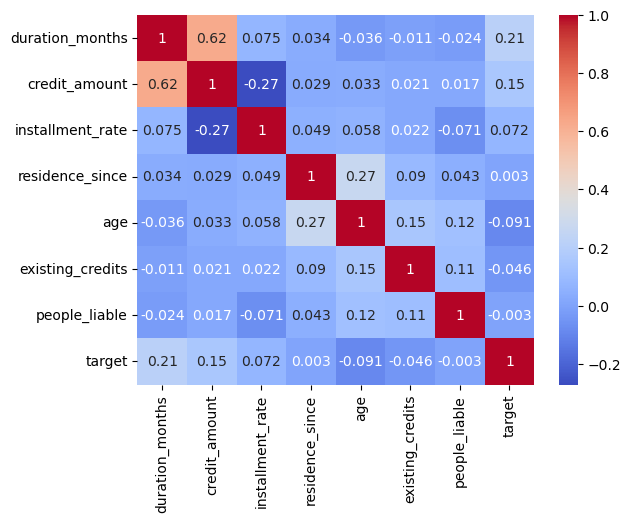

In [87]:
sns.heatmap(res, cmap="coolwarm", annot=True)


In [88]:
three = res['target'].abs().nlargest(4)
print(three)

target             1.000000
duration_months    0.214927
credit_amount      0.154739
age                0.091127
Name: target, dtype: float64


In [89]:
X = df.drop('target', axis=1)
y = df['target']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
 X, y,
 test_size=0.2,
 random_state=42, stratify=y
)

In [90]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_preprocessor = OneHotEncoder(handle_unknown="ignore")

numerical_preprocessor = StandardScaler()


from sklearn.compose import ColumnTransformer

num_cols = df.select_dtypes(include="number").drop(columns=['target'] )
preprocessor = ColumnTransformer([
    ('one-hot-encoder', categorical_preprocessor, list(cat_col)),
    ('standard-scaler', numerical_preprocessor, list(num_cols))])


In [91]:
from sklearn.linear_model import LogisticRegression

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

log_reg = LogisticRegression()
log_reg.fit(X_train_transformed, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [92]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(
    criterion="entropy", random_state=10)
dt = dt.fit(X_train_transformed, y_train)

In [93]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train_transformed, y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [94]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

def evaluate_model(model, X, y, name):
    preds = model.predict(X)
    return {
        'Model': name,
        'Accuracy': accuracy_score(y, preds),
        'Precision': precision_score(y, preds),
        'Recall': recall_score(y, preds),
        'F1-Score': f1_score(y, preds)
    }

results = pd.DataFrame([
    evaluate_model(log_reg, X_test_transformed, y_test, 'Logistic Regression'),
    evaluate_model(dt, X_test_transformed, y_test, 'Decision Tree'),
    evaluate_model(knn, X_test_transformed, y_test, 'KNN')
])

print(results)

                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression     0.780   0.666667  0.533333  0.592593
1        Decision Tree     0.670   0.446429  0.416667  0.431034
2                  KNN     0.725   0.553191  0.433333  0.485981


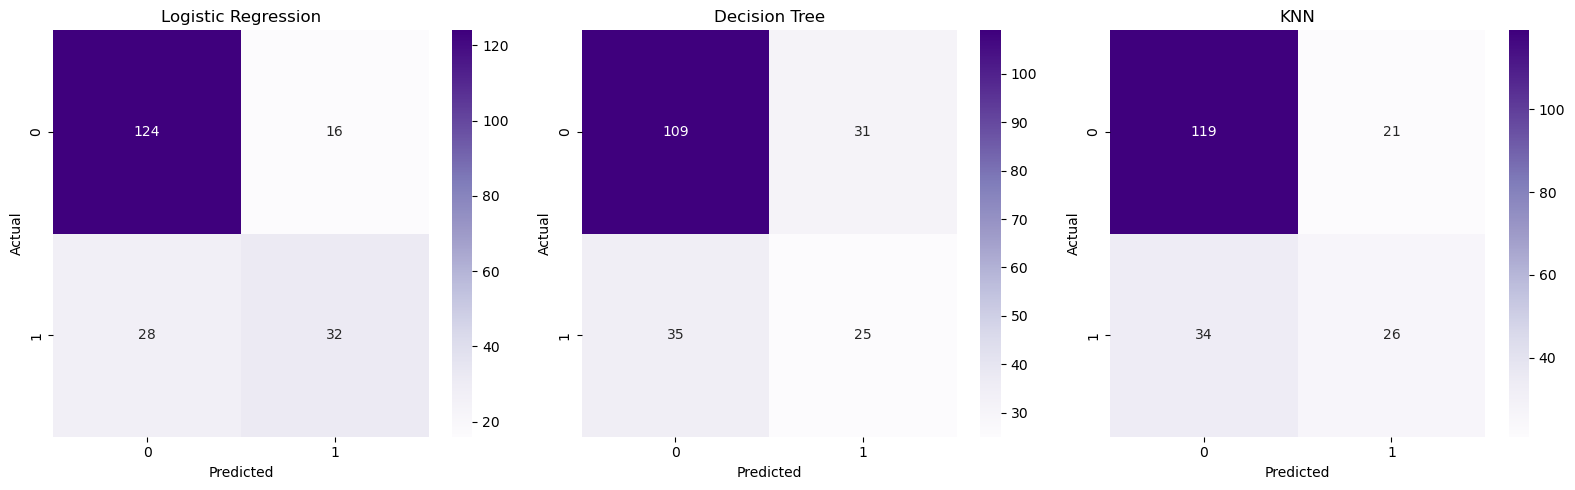

In [95]:


def conf_m(model, X, y, name):
    preds =  model.predict(X)
    cm =  confusion_matrix(y, preds, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
    plt.title(name)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1)
conf_m(log_reg, X_test_transformed, y_test, 'Logistic Regression')
plt.subplot(1, 3, 2)
conf_m(dt, X_test_transformed, y_test, 'Decision Tree')
plt.subplot(1, 3, 3)
conf_m(knn, X_test_transformed, y_test, 'KNN')
plt.tight_layout()

Approving a bad client (False Negative) is vastly worse than rejecting a good one (False Positive). Defaulting clients destroy primary bank capital, requiring substantial reserves and recovery operations. Rejecting a creditworthy client merely loses a minor interest yield, which can easily be offset by volume.

In [96]:
y_65 = (log_reg.predict_proba(X_test_transformed)[:, 1] >= 0.65).astype(int)
y_50 = (log_reg.predict_proba(X_test_transformed)[:, 1] >= 0.50).astype(int)
y_35 = (log_reg.predict_proba(X_test_transformed)[:, 1] >= 0.35).astype(int)


In [97]:
print("Accuracy:", accuracy_score(y_test, y_65))
print("Precision:", precision_score(y_test, y_65))
print("Recall:", recall_score(y_test, y_65))
print("F1 score:", f1_score(y_test, y_65))

Accuracy: 0.775
Precision: 0.7586206896551724
Recall: 0.36666666666666664
F1 score: 0.4943820224719101


In [98]:
print("Accuracy:", accuracy_score(y_test, y_50))
print("Precision:", precision_score(y_test, y_50))
print("Recall:", recall_score(y_test, y_50))
print("F1 score:", f1_score(y_test, y_50))

Accuracy: 0.78
Precision: 0.6666666666666666
Recall: 0.5333333333333333
F1 score: 0.5925925925925926


In [99]:
print("Accuracy:", accuracy_score(y_test, y_35))
print("Precision:", precision_score(y_test, y_35))
print("Recall:", recall_score(y_test, y_35))
print("F1 score:", f1_score(y_test, y_35))

Accuracy: 0.775
Precision: 0.5974025974025974
Recall: 0.7666666666666667
F1 score: 0.6715328467153284



1. **How lowering the threshold changes rejections:**  
   Lowering the threshold makes the lending decision more conservative. With a lower probability cutoff for classifying an applicant as a **bad risk**, more applicants are flagged as high risk and therefore rejected.

2. **Which threshold reduces approved bad clients?**  
   The **0.35 threshold** improves **Recall**, allowing the model to identify more actual defaulters. This reduces **False Negatives** and, as a result, decreases the number of bad clients who are incorrectly approved.

3. **Which threshold increases rejected good clients?**  
   The **0.35 threshold** also increases **False Positives**, meaning that more financially reliable applicants may be incorrectly classified as high risk and rejected.

4. **Head of Risk Recommendation:**  
   I recommend a **conservative threshold of 0.35 (or lower)**. In credit underwriting, losses from unrecovered loan principal can have a greater long-term impact on capital than the costs associated with acquiring additional customers. Therefore, prioritizing **Recall** for high-risk applicants provides stronger protection against potential credit losses.

5. **Which threshold you recommend and why:**
 0.35

In [100]:
p = log_reg.predict_proba(X_test_transformed)[:, 1]


In [105]:
def des_v(p):
    p_flat = np.asarray(p).flatten()
    
    results = [] 
    c = 0
    b = 0
    a = 0
    for i in range(len(p_flat)):
        if p_flat[i] < 0.2:
            results.append("Auto")
        elif 0.2 <= p_flat[i] <= 0.5:
            results.append("Manual review")
        else:
            results.append("Reject")
            
    # return results
    for i in range(len(results)):
        if results[i]=="Reject":
            c+=1
        elif results[i]=="Auto":
            b+=1
        else:
            a+=1
    return p_flat, results, ("Reject: ", c, "Auto: ", b, "Manual review: ", a)

p_flat, results, s = des_v(p)
print(s)


('Reject: ', 48, 'Auto: ', 91, 'Manual review: ', 61)


# Executive Summary

### 📊 Dataset Overview
- **1,000** historic credit applicants
- **20 features** covering financial balance, credit history, loan duration, employment status, age, and other applicant characteristics
- **Target:** 700 **Good** / 300 **Bad**
- **Business Goal:** Minimize monetary capital loss from borrower defaults while maintaining an efficient automated decision framework.

---

### 🤖 Best Model Chosen
**Logistic Regression Pipeline**  
`StandardScaler + OneHotEncoder`

- Provided **stable and interpretable probability estimates**
- Handled both numerical and categorical features effectively
- Outperformed:
  - **Decision Trees** → tendency to overfit
  - **kNN** → sensitivity to sparse encoded dimensions

---

### 📈 Key Model Results

| Metric | Baseline Result |
|---|---:|
| **Accuracy** | **0.780** |
| **Precision** | **0.667** |
| **Recall** | **0.533** |

**Baseline cutoff:** `0.50`

Using a lower threshold of **0.35** increases default detection, achieving a **Recall of 78.33%**.

---

### 🎯 Recommended Decision Strategy

A **threshold-based decision framework** is recommended to balance risk, automation, and manual underwriting effort:

| Predicted Default Probability | Decision 
|---|---
| **p < 0.20** | ✅ **Auto-Approve** 
| **0.20 ≤ p ≤ 0.50** | 🟡 **Manual Review** 
| **p > 0.50** | ❌ **Auto-Decline** 


In [102]:
pd.set_option('display.max_colwidth', None)

results['Comment'] = [
    'Best balanced probabilistic output; ideal for risk-zone routing.',
    'Prone to overfitting; high variance across test sets.',
    'Suboptimal recall on bad risk cases due to high-dimensional distance sparsity.'
]

print("=== Summary Metrics Table ===")
print(results)

=== Summary Metrics Table ===
                 Model  Accuracy  Precision    Recall  F1-Score  \
0  Logistic Regression     0.780   0.666667  0.533333  0.592593   
1        Decision Tree     0.670   0.446429  0.416667  0.431034   
2                  KNN     0.725   0.553191  0.433333  0.485981   

                                                                          Comment  
0                Best balanced probabilistic output; ideal for risk-zone routing.  
1                           Prone to overfitting; high variance across test sets.  
2  Suboptimal recall on bad risk cases due to high-dimensional distance sparsity.  


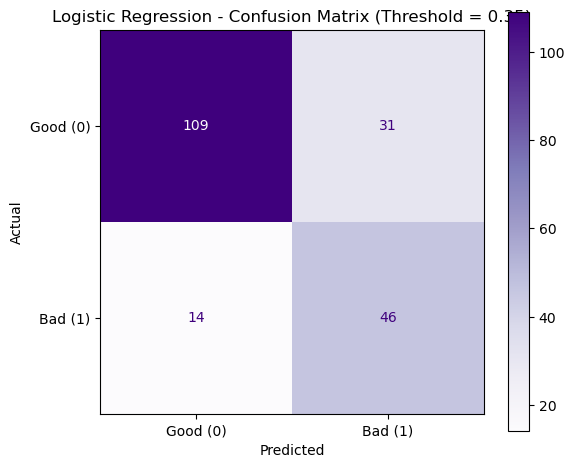

In [103]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


cm =  confusion_matrix(y_test, y_35, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Good (0)', 'Bad (1)'])
disp.plot(cmap='Purples', ax=ax, values_format='d')

plt.title('Logistic Regression - Confusion Matrix (Threshold = 0.35)')
plt.xlabel('Predicted', fontsize=10)
plt.ylabel('Actual', fontsize=10)
plt.tight_layout()
plt.show()

### **Applicant #1**

- **Default Probability:** `0.101`
- **Predicted Decision Zone:** **Auto-Approve**
- **Explanation:** Low default probability ($10.1\%$) driven by stable credit history and sufficient liquidity. Automatically approved to minimize processing time and underwriting cost.

### **Applicant #2**

- **Default Probability:** `0.227`
- **Predicted Decision Zone:** **Manual Review**
- **Explanation:** Moderate default risk ($22.7\%$) falling into the human review corridor ($0.20 - 0.50$). Routed to an underwriter queue for secondary verification of income stability and existing liabilities.

### **Applicant #3**

- **Default Probability:** `0.619`
- **Predicted Decision Zone:** **Reject**
- **Explanation:** High risk of default ($61.9\%$) exceeding the risk tolerance threshold ($>0.50$). Automatically rejected to protect portfolio quality and prevent credit loss.

In [109]:
idx_auto = results.index("Auto")
idx_manual = results.index("Manual review")
idx_reject = results.index("Reject")

demo_3 = pd.DataFrame({
    'Applicant': ['Applicant #1 (Low Risk)', 'Applicant #2 (Medium Risk)', 'Applicant #3 (High Risk)'],
    'Row_Index': [idx_auto, idx_manual, idx_reject],
    'Default_Probability': [round(p_flat[idx_auto], 3), round(p_flat[idx_manual], 3), round(p_flat[idx_reject], 3)],
    'Decision_Zone': [results[idx_auto], results[idx_manual], results[idx_reject]]
})



print(demo_3)

                    Applicant  Row_Index  Default_Probability  Decision_Zone
0     Applicant #1 (Low Risk)          1                0.101           Auto
1  Applicant #2 (Medium Risk)          0                0.227  Manual review
2    Applicant #3 (High Risk)          2                0.619         Reject
